# Лабораторная работа 1. Метод K ближайших соседей

Цель эксперимента — сравнить sklearn и собственную реализацию на классификации переписчиков и оценке мощности волновой фермы. Все варианты оцениваются на одних и тех же объектах.

## Задачи и разбиение


**Avila** содержит десять признаков геометрии текстовых фрагментов латинской рукописи XII века. Классификация по переписчикам позволяет предварительно распределять фрагменты перед проверкой палеографом. Используется разбиение UCI. Номера страниц в признаках отсутствуют, поэтому результаты относятся к этому протоколу и одному манускрипту. [Источник и словарь признаков](https://doi.org/10.24432/C5K02X)

**Wave Energy Converters · Tasmania.** По координатам 16 преобразователей требуется оценить суммарную мощность фермы. Такой прогноз может ускорить отбор вариантов перед запуском гидродинамического симулятора. 16 индивидуальных мощностей исключены: их сумма практически равна целевой переменной. Разбиение учитывает группы конфигураций по координатам, округлённым до 10 м. Соседние конфигурации по разные стороны границы округления могут оказаться в разных частях. Данные охватывают один волновой сценарий. [Источник и схема данных](https://doi.org/10.24432/C5831S)

Обе задачи используют по три внутренних фолда. В каждом фолде масштабирование и модель подгоняются только по его обучающей части. Holdout одинаков для всех пяти работ и используется после выбора конфигураций.

In [1]:
# Загружаем фиксированные разбиения и общие функции эксперимента.
import pandas as pd
from IPython.display import Markdown, display
from labkit.data import load_tasks
from labkit.experiments import (
    comparison_text, describe_data, evaluate_holdout, plot_predictions,
    plot_training, primary_metric, save_scores, select_candidates,
)

LAB = 1
tasks = load_tasks()
display(describe_data(tasks))
for task in tasks:
    display(pd.Series(task.audit, name=task.title).to_frame())

,задача,строк в исходных файлах,train,test,исходные признаки,разбиение
0,Avila — автор фрагмента,20867,10430,10437,10,Официальные train/test; 3 стратифицированных ф...
1,Tasmania — суммарная мощность (МВт),72000,5762,1438,32,Групповой holdout 20% групп; 3 групповых фолда...


,Avila — автор фрагмента
Точных совпадений векторов признаков между train/test,0


,Tasmania — суммарная мощность (МВт)
Строк после проверки диапазонов и пропусков,72000
Точных уникальных конфигураций,72000
Строк в воспроизводимой подвыборке,7200
Групп в подвыборке (округление координат до 10 м),7183


## Выбор метрик


**Avila.** Macro-F1 усредняет F1 по всем 12 классам, сохраняя вклад редких переписчиков. Balanced accuracy — средняя полнота по классам. Accuracy показывает долю верных ответов по всем фрагментам.

**Tasmania.** MAE в МВт показывает средний абсолютный промах. RMSE в тех же единицах сильнее учитывает большие ошибки. R² отражает долю объяснённой вариации относительно среднего отклика теста и может быть отрицательным.

Для проверки полезности моделей используется простой ориентир. Классификационный dummy всегда выбирает самый частый класс train, регрессионный — медиану train. Основные метрики для выбора конфигурации — macro-F1 (выше) и MAE (ниже).

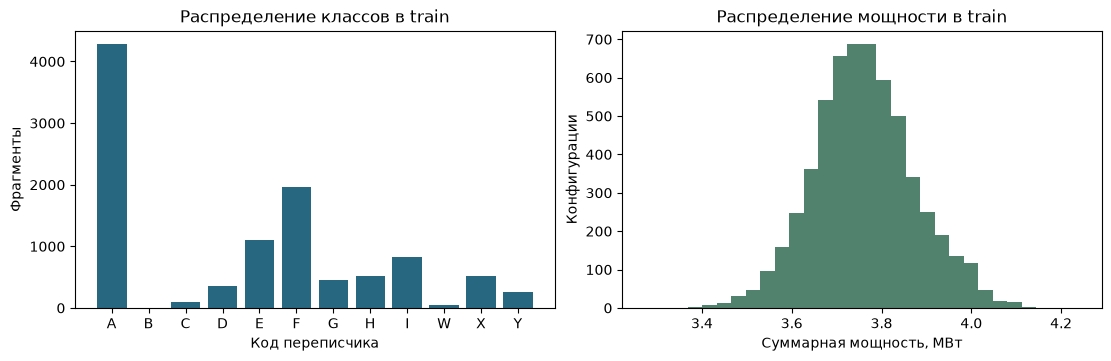

In [2]:
# Изучаем дисбаланс классов и масштаб мощности на обучающих данных.
plot_training(tasks)

## Библиотечный бейзлайн

KNeighborsClassifier и KNeighborsRegressor используют пять ближайших объектов, евклидово расстояние и равные веса. Для классификации прогнозом служит класс с наибольшим числом голосов, для регрессии — среднее соседних откликов.

## Гипотезы и кросс-валидация

В классификации проверяются стандартизация, устойчивое масштабирование, взвешивание голосов по расстоянию и манхэттенская метрика. Стандартизация UCI не исключает разной дисперсии признаков внутри train, а RobustScaler меняет их относительные масштабы при выбросах. В регрессии проверяется, помогает ли сравнивать планировки по геометрическим характеристикам и сглаживать прогноз по большему числу соседей.

В сетку включён бейзлайн. При равенстве средних метрик приоритет получает первая конфигурация. В таблицах приведены оценки каждого фолда и стандартное отклонение между фолдами.

In [3]:
# Проверяем гипотезы на трёх внутренних фолдах и фиксируем победителей.
selections = select_candidates(LAB, tasks)
for task in tasks:
    display(Markdown(f"**{task.title} · {primary_metric(task)}**"))
    display(selections[task.key][2].round(5))

**Avila — автор фрагмента · macro_f1**

,гипотеза,признаки,настройки,CV среднее,CV σ,фолд 1,фолд 2,фолд 3,выбран
0,Бейзлайн,raw,{},0.63366,0.02498,0.64778,0.60481,0.64837,False
1,Стандартизация,standard,{},0.61181,0.01015,0.61311,0.62125,0.60107,False
2,Робастное масштабирование,robust,{},0.82465,0.00993,0.81400,0.82630,0.83365,True
3,k=3 и взвешивание соседей,standard,"{""n_neighbors"": 3, ""weights"": ""distance""}",0.68910,0.02421,0.67751,0.71692,0.67286,False
4,Манхэттенское расстояние и k=11,standard,"{""n_neighbors"": 11, ""p"": 1}",0.57885,0.03049,0.55836,0.61389,0.56430,False


**Tasmania — суммарная мощность (МВт) · mae_mw**

,гипотеза,признаки,настройки,CV среднее,CV σ,фолд 1,фолд 2,фолд 3,выбран
0,Бейзлайн,raw,{},0.05892,0.00182,0.06100,0.05764,0.05813,False
1,Стандартизация координат,standard,{},0.05942,0.00158,0.06116,0.05808,0.05902,False
2,Геометрия со стандартизацией,geometry_standard,{},0.05341,0.00060,0.05334,0.05404,0.05285,False
3,"Геометрия, k=11 и взвешивание",geometry_standard,"{""n_neighbors"": 11, ""weights"": ""distance""}",0.05133,0.00041,0.05134,0.05174,0.05092,True
4,"Координаты, k=11 и взвешивание",raw,"{""n_neighbors"": 11, ""weights"": ""distance""}",0.05821,0.00130,0.05968,0.05722,0.05772,False


## Оценка sklearn на отложенной выборке

Переобучаем бейзлайн и победителя CV на всём train. В итоговом сравнении сохраняем фактический результат даже при снижении качества на holdout.

In [4]:
# Получаем holdout-метрики и сохраняем прогнозы для анализа ошибок.
results = evaluate_holdout(LAB, tasks, selections)
for task in tasks:
    table, _ = results[task.key]
    base = table.loc[table["version"].isin(["dummy", "sklearn baseline", "sklearn tuned"])]
    display(Markdown(f"**{task.title}**"))
    display(base.dropna(axis=1, how="all").drop(columns=["lab", "task", "algorithm"]).round(5))

**Avila — автор фрагмента**

,version,candidate,fit_s,predict_s,macro_f1,balanced_accuracy,accuracy
0,dummy,Мода,NaN,NaN,0.04852,0.08333,0.41065
1,sklearn baseline,Бейзлайн,0.03365,1.01409,0.71828,0.66567,0.74954
2,sklearn tuned,Робастное масштабирование,0.03707,0.56551,0.88331,0.85999,0.86749


**Tasmania — суммарная мощность (МВт)**

,version,candidate,fit_s,predict_s,mae_mw,rmse_mw,r2
0,dummy,Медиана,NaN,NaN,0.08752,0.11228,-0.00000
1,sklearn baseline,Бейзлайн,0.00112,0.05847,0.05975,0.07875,0.50802
2,sklearn tuned,"Геометрия, k=11 и взвешивание",0.16819,0.08735,0.05151,0.06929,0.61922


## Собственная реализация

Собственный KNN хранит обучающую выборку, считает расстояния пакетами, выбирает пять или настроенное число соседей частичной сортировкой и агрегирует их отклики. При весах по расстоянию точные совпадения вытесняют ненулевые расстояния. Равенство на границе k разрешается по порядку train, а равенство голосов — по отсортированному классу. Различия библиотек при равных расстояниях могут влиять на метрики.

Параметры и преобразования переносятся из библиотечного бейзлайна и лучшей библиотечной конфигурации соответственно. Повторного подбора по holdout нет. [Код оценивателей](labkit/models.py)

In [5]:
# Сопоставляем две собственные версии с эквивалентными конфигурациями sklearn.
for task in tasks:
    table, _ = results[task.key]
    models = table.loc[table["version"] != "dummy"]
    display(Markdown(f"**{task.title}**"))
    display(models.dropna(axis=1, how="all").drop(columns=["lab", "task", "algorithm"]).round(5))

**Avila — автор фрагмента**

,version,candidate,fit_s,predict_s,macro_f1,balanced_accuracy,accuracy
1,sklearn baseline,Бейзлайн,0.03365,1.01409,0.71828,0.66567,0.74954
2,sklearn tuned,Робастное масштабирование,0.03707,0.56551,0.88331,0.85999,0.86749
3,own baseline,Бейзлайн,0.00477,2.24059,0.71828,0.66567,0.74954
4,own tuned,Робастное масштабирование,0.01439,2.09308,0.88331,0.85999,0.86749


**Tasmania — суммарная мощность (МВт)**

,version,candidate,fit_s,predict_s,mae_mw,rmse_mw,r2
1,sklearn baseline,Бейзлайн,0.00112,0.05847,0.05975,0.07875,0.50802
2,sklearn tuned,"Геометрия, k=11 и взвешивание",0.16819,0.08735,0.05151,0.06929,0.61922
3,own baseline,Бейзлайн,0.00055,0.32010,0.05975,0.07875,0.50802
4,own tuned,"Геометрия, k=11 и взвешивание",0.15452,0.24795,0.05151,0.06929,0.61922


## Диагностика ошибок

Матрица ошибок нормирована по истинному классу. Точки на графике мощности сравниваются с диагональю идеального прогноза. Обе визуализации относятся к варианту sklearn, выбранному по CV.

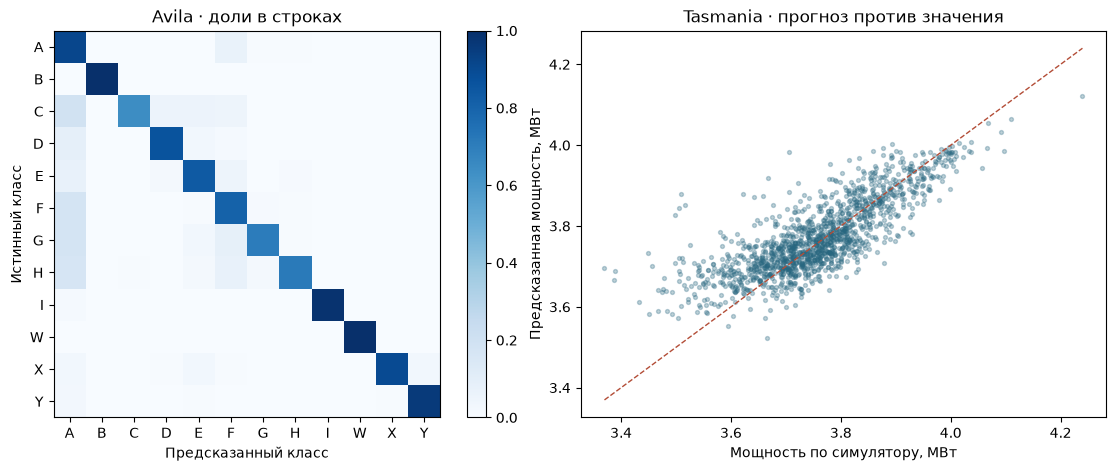

In [6]:
# Визуализируем ошибки классификации и отклонения мощности на holdout.
plot_predictions(tasks, results)

## Выводы

In [7]:
# Формируем вывод из измеренных метрик и экспортируем входные данные для сводки.
display(Markdown(comparison_text(tasks, results, selections)))
relative_path = save_scores(LAB, results)
print(f"Метрики сохранены в {relative_path.as_posix()}")

**Avila — автор фрагмента.** По CV выбран вариант «Робастное масштабирование» (macro-F1 0.8247, бейзлайн 0.6337). На holdout macro-F1 sklearn улучшился относительно бейзлайна: 0.7183 → 0.8833. Собственная реализация: 0.7183 → 0.8833. Разница собственной модели и sklearn macro-F1: +0.0000 в бейзлайне, +0.0000 после настройки.

**Tasmania — суммарная мощность (МВт).** По CV выбран вариант «Геометрия, k=11 и взвешивание» (MAE 0.0513 МВт, бейзлайн 0.0589 МВт). На holdout MAE sklearn улучшился относительно бейзлайна: 0.0598 → 0.0515 МВт. Собственная реализация: 0.0598 → 0.0515 МВт. Разница собственной модели и sklearn MAE: +0.0000 МВт в бейзлайне, -0.0000 МВт после настройки.

Метрики сохранены в results/lab_01.csv
